# **Lab 2: Supervised Learning**
---

**5. Load Required Libraries**

In [206]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
 mean_absolute_error,
 mean_squared_error,
 r2_score
)

**6. Load and Inspect the Dataset**

In [207]:
df = pd.read_csv("power_plant.csv")
print(df.head()) #display first 5 rows
print(df.shape)
print(df.columns)
print(df.describe())
print(df.info())
print(df.isnull().sum())


      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90
(9568, 5)
Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 ent

**Questions**

Q1. How many observations are in the dataset?
> There are 9568 observations in the dataset.

Q2. How many input variables are used?
>There are 4 variables (AT, V, AP, and RH)

Q3. Which variable are you trying to predict?
> I am trying to predict the "PE" variables, that corresponds to the Electrical Power Output.

Q4. Is this a regression or classification problem? Explain why
>It is a linear regression problem, since the value we are prediciting is a numerical and continuos value, which is PE.

---

**7. Visualize the Engineering Relationships**

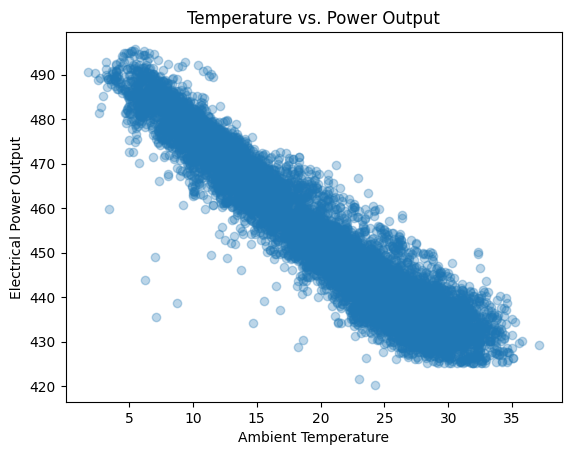

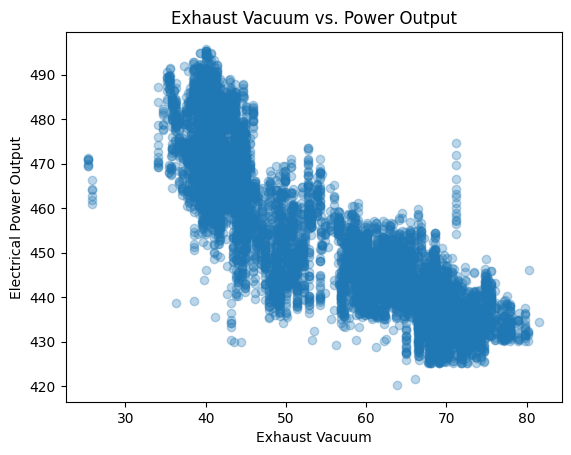

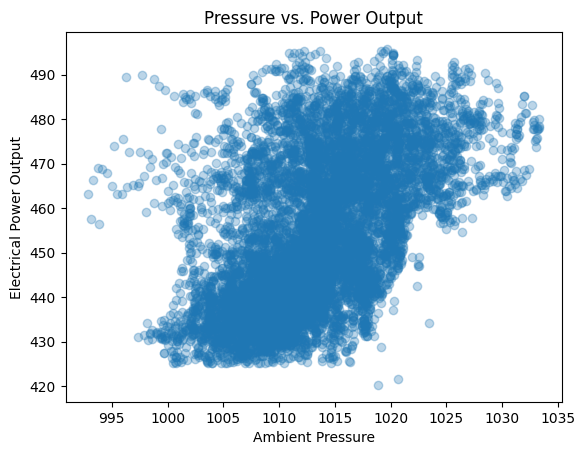

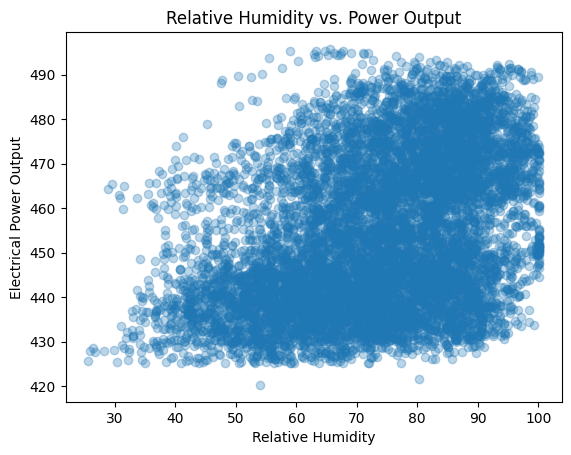

In [208]:
plt.scatter(df["AT"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Temperature")
plt.ylabel("Electrical Power Output")
plt.title("Temperature vs. Power Output")
plt.show()

plt.scatter(df["V"], df["PE"], alpha=0.3)
plt.xlabel("Exhaust Vacuum")
plt.ylabel("Electrical Power Output")
plt.title("Exhaust Vacuum vs. Power Output")
plt.show()

plt.scatter(df["AP"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Pressure")
plt.ylabel("Electrical Power Output")
plt.title("Pressure vs. Power Output")
plt.show()

plt.scatter(df["RH"], df["PE"], alpha=0.3)
plt.xlabel("Relative Humidity")
plt.ylabel("Electrical Power Output")
plt.title("Relative Humidity vs. Power Output")
plt.show()


**Q5.** Which variable appears to have the strongest visible relationship with power output?
> The AT (Ambient Temperature) has the strongest relationship with the Power Output. This system converts Thermal Energy into Electrical Power, so Temperature might impact heavily on the result.

**Q6** Is the relationship approximately linear for every variable?
> The variables that expose a clear negative linear relationship with the PE (Electrical Power Output) are the AT (Ambient Temperature) and the V (Exhaust Vacuum), it is not clearly linear for the other variables.
---

**8. Define Inputs and Target**

In [209]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

**9. Split the data**

In [210]:
X_train, X_temp, y_train, y_temp = train_test_split(
 X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
 X_temp, y_temp, test_size=0.50, random_state=42
)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 6697
Validation: 1435
Testing: 1436


**10. Standardize the inputs**

In [211]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

**11. Build the Baseline model**

In [212]:
baseline = LinearRegression()
baseline.fit(X_train_scaled, y_train)

LinearRegression()

**12. Make validation predictions**

In [213]:
y_val_pred = baseline.predict(X_val_scaled)
comparison = pd.DataFrame({
 "Actual": y_val.values[:10],
 "Predicted": y_val_pred[:10]
})
print(comparison)

   Actual   Predicted
0  440.74  435.036365
1  432.09  433.789650
2  486.14  479.102298
3  442.75  439.039845
4  437.61  433.180482
5  481.77  476.246414
6  437.41  436.327719
7  465.95  466.500630
8  439.18  444.786069
9  438.42  438.915509


**Q7.** Are the predicted values reasonably close the the actual values?
> Yes, the values between actual and predicted, and the largest error among the 10 samples is approximately a difference of 7 (486.14-479.10).
---

**13. Evaluate the regression model**

In [214]:
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(
 mean_squared_error(y_val, y_val_pred)
)
r2 = r2_score(y_val, y_val_pred)
print("MAE :", mae)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 3.645222450684648
RMSE: 4.562690287171953
R^2 : 0.930078295626855


| Metric | Linear Regression |
|-------|---------------|
| MAE |3.6452|
| RMSE |4.5627|
| R^2 |0.9301|
---

**14. Plot Actual vs Predicted Values**

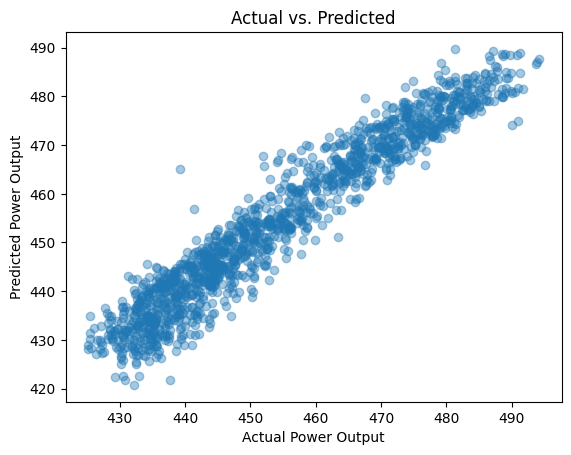

In [215]:
plt.scatter(y_val, y_val_pred, alpha=0.4)
plt.xlabel("Actual Power Output")
plt.ylabel("Predicted Power Output")
plt.title("Actual vs. Predicted")
plt.show()

**15. Examine the Prediction Errors**

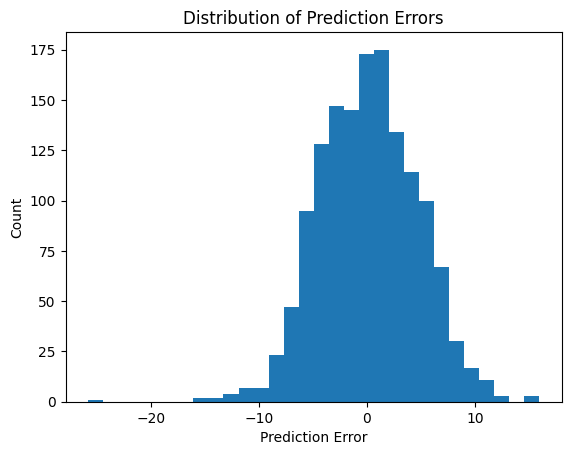

In [216]:
residuals = y_val.values - y_val_pred
plt.hist(residuals, bins=30)
plt.xlabel("Prediction Error")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors")
plt.show()

**Q8.** Are the errors approximately centered around zero?
> Yes, based on the distribution chart, most of the errors are centered around zero, which means that the model consistenly is close to the actual answer (Power Output).

**Q9.** Are there any unusually large errors?
> Yes, there are a few unusual errors shown in the distribution chart.
---

**16. Engineering Interpretation**

Suppose the baseline model has an MAE of approximately 4 MW. This means its predictions differ from the actual power output by about 4 MW on average.

**Q10.** Would an average prediction error of approximately 4 MW be acceptable for every power-plant application? Explain briefly.
>  No, an average of 4MW is not acceptable for each power plant. Power plants have different sizes, output targets, etc, therefore, the error cannot be generalized, since it could lead to operational problems.

---

# Lab 3: Shallow Neural Network

**17. Move beyond linear regression**

**19. Import PyTorch and Convert the data**

In [217]:
import torch
import torch.nn as nn
torch.manual_seed(42)
X_train_t = torch.tensor(
 X_train_scaled, dtype=torch.float32
)
y_train_t = torch.tensor(
 y_train.values, dtype=torch.float32
).reshape(-1, 1)
X_val_t = torch.tensor(
 X_val_scaled, dtype=torch.float32
)
y_val_t = torch.tensor(
 y_val.values, dtype=torch.float32
).reshape(-1, 1)

**20. Define the Shallow Neural Network**

In [218]:
model = nn.Sequential(
 nn.Linear(4, 64),
 nn.ReLU(),
 nn.Linear(64, 1)
)
print(model)


Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=1, bias=True)
)


**Q11.** What would happen if the ReLU activation were removed and only linear layers remained?
> If the ReLU activation function is removed from the code, the output of the first linear layer would still be linear when it goes into the next one. Therefore, the model would not learn about non-linearity, which is what the ReLU does.
---

**21. Define the Loss Function and Optimizer**

In [219]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.1
)

**22. Train the Network**

In [220]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
    model.train()
    prediction = model(X_train_t)
    loss = loss_fn(
        prediction,
        y_train_t
    )
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_prediction = model(X_val_t)
        val_loss = loss_fn(
            val_prediction,
            y_val_t
        )
    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    if epoch % 50 == 0:
        print(epoch, loss.item(), val_loss.item())

0 206925.03125 205116.09375
50 2464.39697265625 2485.21142578125
100 265.61285400390625 259.2077331542969
150 77.3603744506836 78.36669921875
200 39.231689453125 40.23942184448242
250 27.839174270629883 28.689855575561523


**23. Plot the Learning Curves**

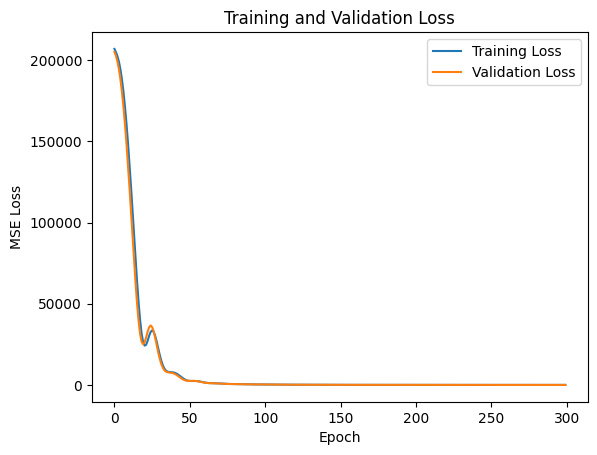

In [221]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()


**Q12.** What happened to the training loss as training progressed?
>As the training progressed the loss decreased on each epoch, which is an indication that the model is reducing the losses and learning.

**Q13.** What happened to the validation loss?
> The Validation loss in the model decreased on each epoch too, which means that the predictions on the validation was improving.

**Q14.** Did the two curves behave similarly?
> Yes, based on the plot both curves behave similarly, both of them decreased at a similar rate and are close to each other.
---

**25. Evaluate the Neural Network**

In [222]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

MAE : 3.7811948369787123
RMSE: 4.924556976007735
R^2 : 0.9185475112286153


**26. Compare the Models**

Note: The values below correspond to the values before doing Experiment 1, therefore the values printed on the above code might be different from the ones on the table below.

| Metric | Linear Regression | Shallow NN |
|-------|---------------|--------------|
| MAE |3.6452|137.1613|
| RMSE |4.5627|161.3431|
| R^2 |0.9301|-86.432|

**Q15.** Which model has the smaller MAE?
> Linear Regression model (3.6452)

**Q16.** Which model has the smaller RMSE?
> Linear Regression model (4.5627)

**Q17.** Which model has the higher R^2?
> Linear Regression model (0.9301)

---

**27. Is the Neural Network Actually Better?**

**Q18.** Does the performance improvement of your neural network justify its additional complexity? Use your results.
> No, it does not justify the complexity. Depending on the problem presented simpler models might perform better without much tunning that complex models, which was the case on this example, since the Linear Regression Model had performed better with lower MAE, RMSE and R^2.

---

**28. Experiment 1 - Number of Hidden Neurons**

Repeat training with 4, 16, and 64 hidden neurons. Record the validation metrics.

| Hidden Neurons | Validation MAE | Validation RMSE |
|-------|---------------|--------------|
| 4 |331.253|361.855|
| 16 |137.161|161.343|
| 64 |58.317|69.489|

**Q19.** Does increasing the number of hidden neurons always improve validation performance?
> On this experiment increasing the # of hidden neurosn improved the results of the MAE and RMSE but it does not mean that it would always be the case. When performing the experiment with more neurons, the computational cost would increase, but it does not necessarely performed better than linear regression.

---

**29. Experiment 2 - Learning Rate**

Restore the 16-neuron model. Repeat training with the following learning rates:

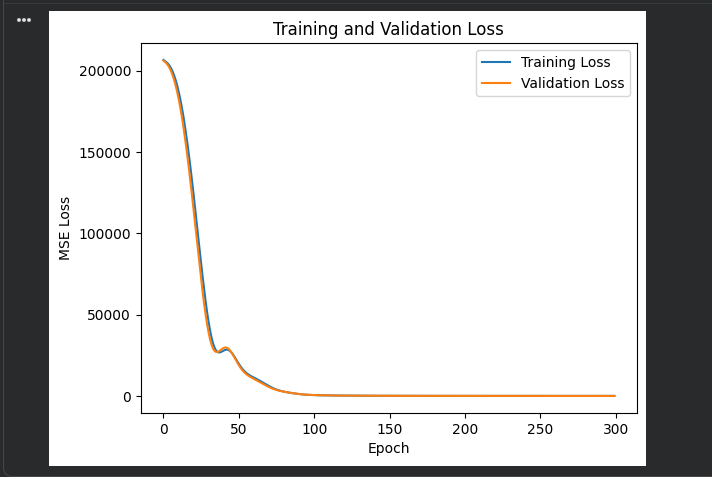

Learning Rate: 0.1


In [223]:
from IPython.display import Image, display
display(Image("/content/Images/lr0.1.png"))
print("Learning Rate: 0.1")

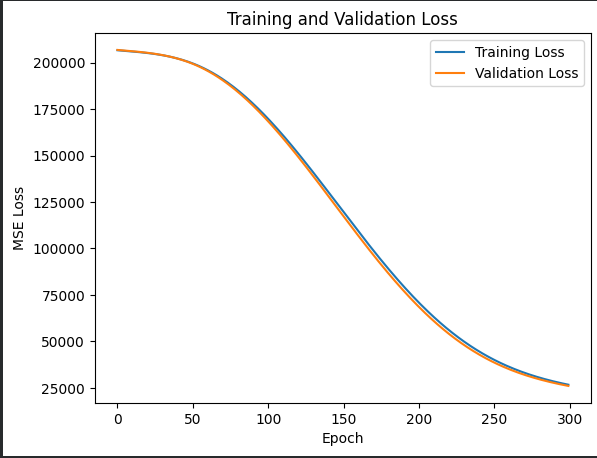

Learning Rate: 0.01


In [224]:
display(Image("/content/Images/lr0.01.png"))
print("Learning Rate: 0.01")

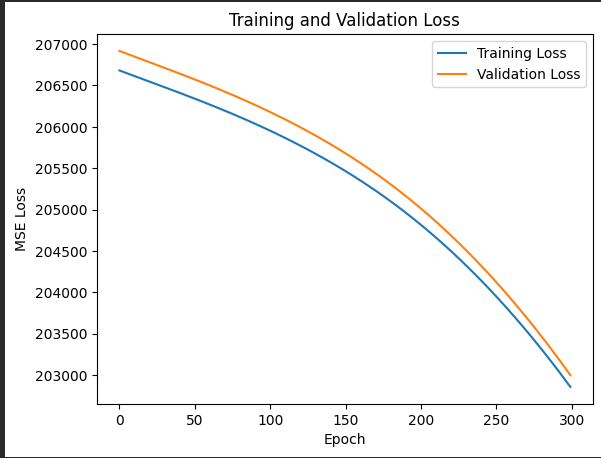

Learning Rate: 0.001


In [225]:
display(Image("/content/Images/lr0.001.png"))
print("Learning Rate: 0.001")

**Q20.** What happens when the learning rate is too large?
> In this specific case, the largest learning rate of 0.1 is the shows better performance because the losses decreased faster in less runs (Epoch) in both training and validation.

Q21. What happens when it is very small?
> When the value is very small (0.001) the losses decreased slowly, which means that it needed more epochs to reach a MSE loss, which is still higher comparted to the close to 0 MSE Losses obtained by using a learning rate of 0.1

---

**30. Final Model Selection**


| Configuration | Selected Value |
|-------|---------------|
| Hidden Neurons |64|
| Learning Rate |0.1|
| Epochs |300|


**31. Final Test Evaluation**


In [226]:
X_test_t = torch.tensor(
 X_test_scaled, dtype=torch.float32
)
model.eval()
with torch.no_grad():
 y_test_nn = model(X_test_t)
y_test_nn = y_test_nn.numpy().flatten()

In [227]:
# Predict using linear regression
y_test_lr = baseline.predict(X_test_scaled)

# Calculate test metrics for both models
results = pd.DataFrame({
    "Metric": ["Test MAE", "Test RMSE", "Test R^2"],
    "Linear Regression": [
        mean_absolute_error(y_test, y_test_lr),
        np.sqrt(mean_squared_error(y_test, y_test_lr)),
        r2_score(y_test, y_test_lr)
    ],
    "Shallow NN": [
        mean_absolute_error(y_test, y_test_nn),
        np.sqrt(mean_squared_error(y_test, y_test_nn)),
        r2_score(y_test, y_test_nn)
    ]
})

print(results)

      Metric  Linear Regression  Shallow NN
0   Test MAE           3.654640    3.753731
1  Test RMSE           4.654168    4.932491
2   Test R^2           0.924857    0.915601


Calculate MAE, RMSE, and R^2 on the test set for both the final neural network and the linear-regression baseline.


| Metric   | Linear Regression | Shallow NN |
|----------|-------------------:|-----------:|
| Test MAE | 3.654640           | 3.753731   |
| Test RMSE| 4.654168           | 4.932491   |
| Test R²  | 0.924857           | 0.915601   |
---

**33. Final Engineering Analysis**

**Q22.** Which model performed better on the final test set?
> At the end, the linear regression model performed better, but the Shallow NN might be tuned to performed better that the Linear Regression.

**Q23.** Was the improvement substantial or small?
> After changing the parameters in the Shallow NN model, the improvement was substantial, but it did not surpass the performance of the Linear Regression Model



In [229]:
errors_nn = np.abs(y_test.values - y_test_nn)
errors_lr = np.abs(y_test.values - y_test_lr)

print("Largest NN error:", errors_nn.max())
print("Largest Linear Regression error:", errors_lr.max())

Largest NN error: 39.78611328124998
Largest Linear Regression error: 38.58948543789302


**Q24.** What is the largest prediction error you observed?
> The largest error between the PE was 39.786 from the Shallow NN.

**Q25.** What engineering conditions might make prediction more difficult? Consider factors not represented in the four inputs.
> Predictions might become difficult if the the plant operating conditions are not fully defined in the 4 variables. In a power plant there are other variables that might affect the PE values, such as System Maintenance, fuel quality and other variables.
---

# **Engineering Reflection**

**R1.** Why is low training error alone insufficient evidence that a model is useful?
> Low training error does not mean that it would perform good on new data or in the testing phase, since there might be overfitted data and it is not generalizing good enough.

**R2.** Why should preprocessing parameters such as normalization statistics be calculated using only training data?
> Preprocessing parameters is done only in the training data to avoid data leakage and bias on our results. Using information from the validation or test would give information to our model that must not be seen until testing.

**R3.** What is the purpose of the validation dataset?
> The validation dataset allow us to evaluate the model during the development phase (before testing), and compare different configurations such as number of neurosn, learning rate, epochs, etc. Therefore, it helps to choose the best parameter options for our model.

**R4.** What is the purpose of the test dataset?
> The purpose of the test data set is to evaluate our final model with data that it has not seen yet, which helps to compare how well the model performs with unseen data.

**R5.** Why might a simpler model sometimes be preferable even if a neural network performs slightly better?
> A simpler model might be preferrable since it easier faster, easier to understand and mantain. Neural Network are complex and increase the computational cost, which sometimes is not desirable, depending on the resources available.

**R6.** What evidence would you want before deploying this model in a real power plant?
> Before implementing the model in a real power plant, I would test the model in unseen and rare operational conditions to see if the PE values are still reliable and the error is not high. Since other operational conditions might have an impact, I would explore these other variables and see if they have a huge impact on the final predictions.

**Final engineering question:**
Does the additional complexity of the model produce enough practical benefit to justify using it?
> No, it does not produce a practical benefit. Sometimes projects are limited by resources and if a simpler model performs closely to the complex models, it is practical enough depending on the application.